# Clean, Explore & Engineer — Breast Cancer Wisconsin (Diagnostic)

**Goal:** (a) handle missing values, duplicates and outliers, (b) run EDA with 4+ visualizations, (c) engineer 2+ features for a future diagnosis classifier, and (d) summarize 5 key insights.

**Dataset:** 569 fine-needle-aspirate (FNA) samples of breast masses. Each row has an `id`, a `diagnosis` (**M** = malignant, **B** = benign) and 30 numeric features: 10 cell-nucleus measurements (radius, texture, perimeter, area, smoothness, compactness, concavity, concave points, symmetry, fractal dimension), each reported as `_mean`, `_se` (standard error) and `_worst` (mean of the three largest values).

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid", palette="Set2")
plt.rcParams["figure.dpi"] = 110
pd.set_option("display.max_columns", 40)

df_raw = pd.read_csv("data.csv")   # in Colab: upload data.csv to the session first
print("Shape:", df_raw.shape)
df_raw.head()

Shape: (569, 33)


,id,diagnosis,radius_mean,texture_mean,perimeter_mean,area_mean,smoothness_mean,compactness_mean,concavity_mean,concave points_mean,symmetry_mean,fractal_dimension_mean,radius_se,texture_se,perimeter_se,area_se,smoothness_se,compactness_se,concavity_se,concave points_se,symmetry_se,fractal_dimension_se,radius_worst,texture_worst,perimeter_worst,area_worst,smoothness_worst,compactness_worst,concavity_worst,concave points_worst,symmetry_worst,fractal_dimension_worst,Unnamed: 32
0,842302,M,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,0.07871,1.0950,0.9053,8.589,153.40,0.006399,0.04904,0.05373,0.01587,0.03003,0.006193,25.38,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890,NaN
1,842517,M,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,0.05667,0.5435,0.7339,3.398,74.08,0.005225,0.01308,0.01860,0.01340,0.01389,0.003532,24.99,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902,NaN
2,84300903,M,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,0.05999,0.7456,0.7869,4.585,94.03,0.006150,0.04006,0.03832,0.02058,0.02250,0.004571,23.57,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758,NaN
3,84348301,M,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,0.2597,0.09744,0.4956,1.1560,3.445,27.23,0.009110,0.07458,0.05661,0.01867,0.05963,0.009208,14.91,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300,NaN
4,84358402,M,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,0.1809,0.05883,0.7572,0.7813,5.438,94.44,0.011490,0.02461,0.05688,0.01885,0.01756,0.005115,22.54,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678,NaN


## 1. Data Cleaning

### 1a. Structure & data types

In [2]:
df_raw.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 569 entries, 0 to 568
Data columns (total 33 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   id                       569 non-null    int64  
 1   diagnosis                569 non-null    object 
 2   radius_mean              569 non-null    float64
 3   texture_mean             569 non-null    float64
 4   perimeter_mean           569 non-null    float64
 5   area_mean                569 non-null    float64
 6   smoothness_mean          569 non-null    float64
 7   compactness_mean         569 non-null    float64
 8   concavity_mean           569 non-null    float64
 9   concave points_mean      569 non-null    float64
 10  symmetry_mean            569 non-null    float64
 11  fractal_dimension_mean   569 non-null    float64
 12  radius_se                569 non-null    float64
 13  texture_se               569 non-null    float64
 14  perimeter_se             5

### 1b. Missing values

In [3]:
missing = df_raw.isna().sum()
missing[missing > 0]

,0
Unnamed: 32,569


The only missing values are in **`Unnamed: 32`**, which is 100% empty: an artifact of a trailing comma in the CSV header, not real data. It is dropped. No other column has nulls, so no imputation is needed.

`id` is a sample identifier with no predictive meaning; I keep it for the duplicate check, then drop it.

In [4]:
df = df_raw.drop(columns=["Unnamed: 32"]).copy()

# Clean up column names: 'concave points_mean' -> 'concave_points_mean'
df.columns = df.columns.str.strip().str.replace(" ", "_")
print("Remaining nulls:", df.isna().sum().sum())

Remaining nulls: 0


### 1c. Duplicates

In [5]:
print("Fully duplicated rows:", df.duplicated().sum())
print("Duplicated ids       :", df["id"].duplicated().sum())
print("Duplicate feature rows (ignoring id):", df.drop(columns="id").duplicated().sum())

Fully duplicated rows: 0
Duplicated ids       : 0
Duplicate feature rows (ignoring id): 0


No duplicates at any level, so nothing to remove. Now drop `id` and encode the target.

In [6]:
df = df.drop(columns="id")
df["target"] = (df["diagnosis"] == "M").astype(int)   # 1 = malignant
features = [c for c in df.columns if c not in ("diagnosis", "target")]
print(len(features), "numeric features")
df["diagnosis"].value_counts()

30 numeric features


,count
diagnosis,
B,357
M,212


### 1d. Zero values: missing in disguise?

In [7]:
zeros = (df[features] == 0).sum()
zeros[zeros > 0]

,0
concavity_mean,13
concave_points_mean,13
concavity_se,13
concave_points_se,13
concavity_worst,13
concave_points_worst,13


In [ ]:
# Are the zeros the same 13 samples across all six concavity columns?
zero_rows = df[df["concavity_mean"] == 0]
print("Rows with concavity_mean == 0:", len(zero_rows))
print(zero_rows["diagnosis"].value_counts())
zero_rows[["radius_mean", "concavity_mean", "concave_points_mean", "concavity_worst"]].describe().loc[["mean", "min", "max"]]

Rows with concavity_mean == 0: 13
diagnosis
B    13
Name: count, dtype: int64


,radius_mean,concavity_mean,concave_points_mean,concavity_worst
mean,9.411,0.0,0.0,0.0
min,6.981,0.0,0.0,0.0
max,12.270,0.0,0.0,0.0


The 13 zero rows are the **same samples** in all six concavity / concave-points columns, are all benign, and are small, smooth nuclei. A nucleus with no concave contour sections legitimately scores 0 on these measures, so these are **valid values, not hidden missing data**. They are kept as-is.

### 1e. Outliers (IQR method)

In [ ]:
q1, q3 = df[features].quantile(0.25), df[features].quantile(0.75)
iqr = q3 - q1
lower, upper = q1 - 1.5 * iqr, q3 + 1.5 * iqr
is_out = (df[features] < lower) | (df[features] > upper)

out_counts = is_out.sum().sort_values(ascending=False)
print("Rows with at least one IQR outlier:", is_out.any(axis=1).sum(), "of", len(df))
out_counts.head(10)

Rows with at least one IQR outlier: 171 of 569


area_se                    65
radius_se                  38
perimeter_se               38
area_worst                 35
smoothness_se              30
fractal_dimension_se       28
compactness_se             28
symmetry_se                27
area_mean                  25
fractal_dimension_worst    24
dtype: int64

In [ ]:
# Who are the outliers?  Compare class mix of outlier rows vs. the whole dataset
any_out = is_out.any(axis=1)
pd.DataFrame({
    "% malignant (outlier rows)": [df.loc[any_out, "target"].mean() * 100],
    "% malignant (all rows)":     [df["target"].mean() * 100],
}).round(1)

,% malignant (outlier rows),% malignant (all rows)
0,66.7,37.3


**Decision:** about 30% of rows contain at least one IQR outlier, and those rows are much more likely to be malignant. Large, irregular nuclei are *exactly* the signal a diagnostic model needs, so dropping them would delete the minority class and bias the model. Instead:

- **Raw values are kept** for EDA (`df`).
- A **modeling copy** (`df_model`) caps each feature at its 1st / 99th percentile (winsorizing). This tames the few extreme points that could dominate distance- or gradient-based models without removing any sample.

In [8]:
p01, p99 = df[features].quantile(0.01), df[features].quantile(0.99)
df_model = df.copy()
df_model[features] = df_model[features].clip(lower=p01, upper=p99, axis=1)

changed = (df_model[features] != df[features]).sum().sum()
print(f"Values capped: {changed} of {df[features].size} ({changed / df[features].size:.1%})")
print("Rows kept:", len(df_model))

Values capped: 324 of 17070 (1.9%)
Rows kept: 569


## 2. Exploratory Data Analysis

### Chart 1 — Class balance (count plot)

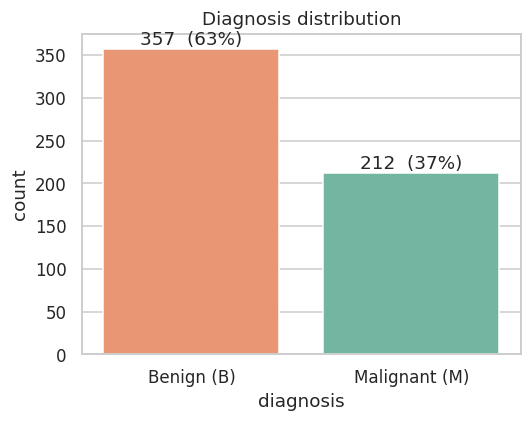

In [9]:
fig, ax = plt.subplots(figsize=(5, 4))
order = ["B", "M"]
sns.countplot(data=df, x="diagnosis", order=order, ax=ax, hue="diagnosis", legend=False)
for p in ax.patches:
    h = p.get_height()
    ax.annotate(f"{int(h)}  ({h / len(df):.0%})", (p.get_x() + p.get_width() / 2, h),
                ha="center", va="bottom")
ax.set_title("Diagnosis distribution")
ax.set_xticks([0, 1], ["Benign (B)", "Malignant (M)"])
plt.tight_layout(); plt.show()

Moderately imbalanced (~63% benign / 37% malignant). A future model should use a stratified split and track recall / F1 for the malignant class, not just accuracy.

### Chart 2 — Feature distributions by diagnosis (histograms)

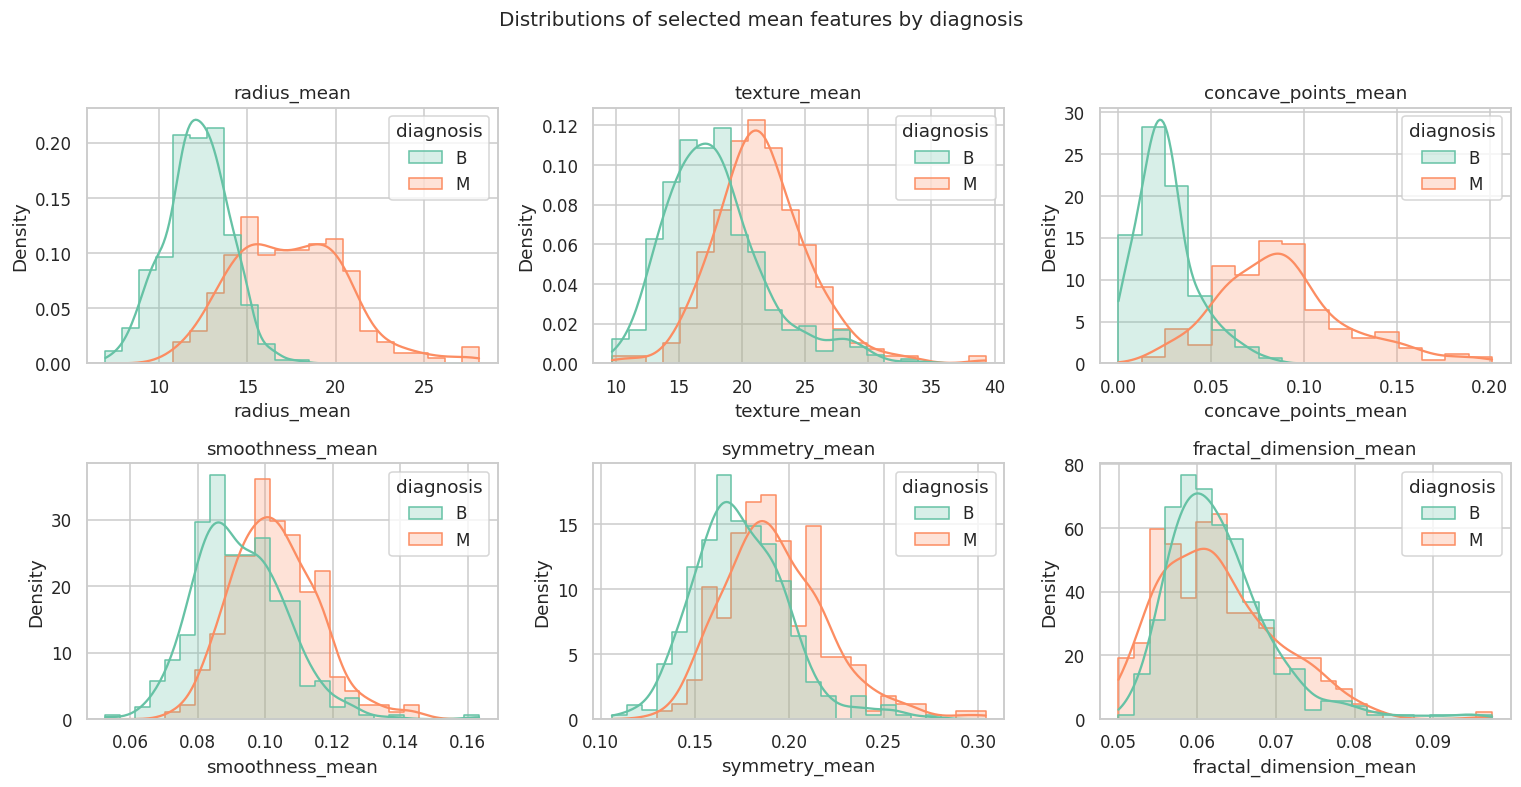

In [10]:
key = ["radius_mean", "texture_mean", "concave_points_mean",
       "smoothness_mean", "symmetry_mean", "fractal_dimension_mean"]
fig, axes = plt.subplots(2, 3, figsize=(14, 7))
for ax, col in zip(axes.ravel(), key):
    sns.histplot(data=df, x=col, hue="diagnosis", hue_order=order,
                 kde=True, element="step", stat="density", common_norm=False, ax=ax)
    ax.set_title(col)
fig.suptitle("Distributions of selected mean features by diagnosis", y=1.02, fontsize=13)
plt.tight_layout(); plt.show()

Size and shape features (`radius_mean`, `concave_points_mean`) separate the classes clearly, with little overlap. `texture_mean` shifts right for malignant cases but overlaps more. `symmetry_mean` and especially `fractal_dimension_mean` overlap almost completely, so on their own they add little.

### Chart 3 — Group comparison (boxplots, standardized)

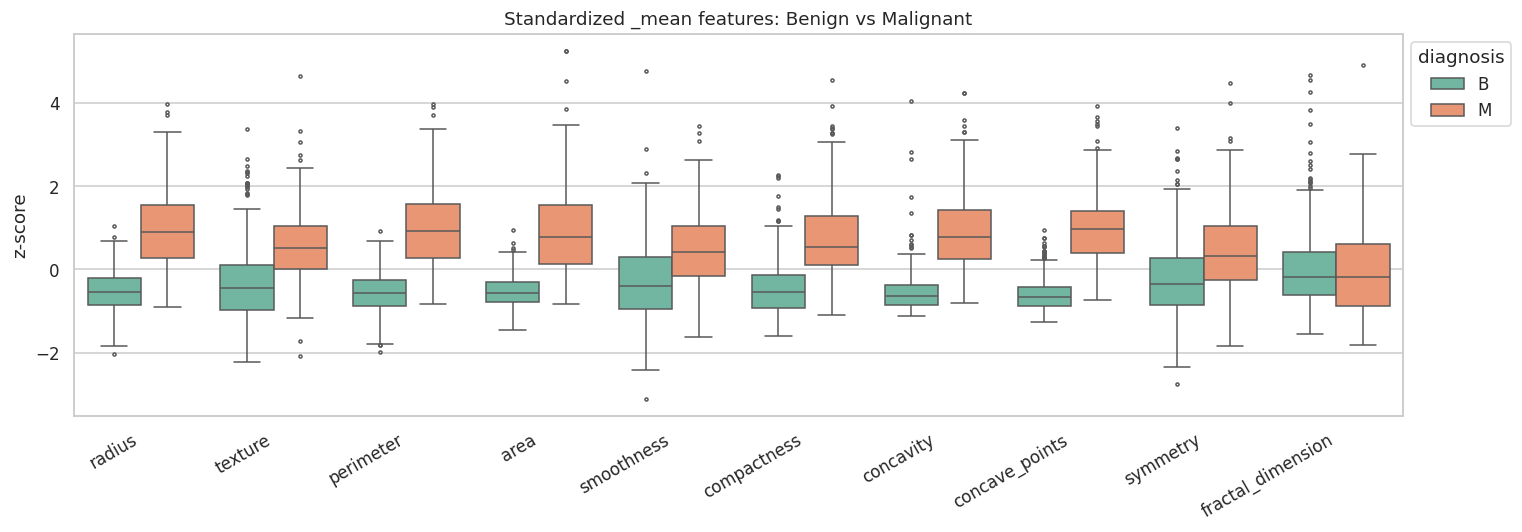

In [11]:
mean_cols = [c for c in features if c.endswith("_mean")]
z = (df[mean_cols] - df[mean_cols].mean()) / df[mean_cols].std()
z_long = z.assign(diagnosis=df["diagnosis"]).melt(id_vars="diagnosis",
                                                  var_name="feature", value_name="z_score")
z_long["feature"] = z_long["feature"].str.replace("_mean", "")

fig, ax = plt.subplots(figsize=(14, 5))
sns.boxplot(data=z_long, x="feature", y="z_score", hue="diagnosis", hue_order=order,
            fliersize=2, ax=ax)
ax.legend(title="diagnosis", loc="upper left", bbox_to_anchor=(1, 1))
ax.set_title("Standardized _mean features: Benign vs Malignant")
ax.set_xlabel(""); ax.set_ylabel("z-score")
plt.xticks(rotation=30, ha="right"); plt.tight_layout(); plt.show()

In [12]:
# Numeric backing for the boxplot: class medians and their ratio
med = df.groupby("diagnosis")[mean_cols].median().T
med["M / B ratio"] = (med["M"] / med["B"]).round(2)
med.sort_values("M / B ratio", ascending=False)

diagnosis,B,M,M / B ratio
concavity_mean,0.03709,0.151350,4.08
concave_points_mean,0.02344,0.086280,3.68
area_mean,458.40000,932.000000,2.03
compactness_mean,0.07529,0.132350,1.76
perimeter_mean,78.18000,114.200000,1.46
radius_mean,12.20000,17.325000,1.42
texture_mean,17.39000,21.460000,1.23
smoothness_mean,0.09076,0.102200,1.13
symmetry_mean,0.17140,0.189900,1.11
fractal_dimension_mean,0.06154,0.061575,1.00


Most of the outliers in the boxplots sit on the malignant side, which confirms the decision not to drop them. Concavity and concave points show the largest relative gap between classes; the malignant median is several times the benign one.

### Chart 4 — Correlation heatmap

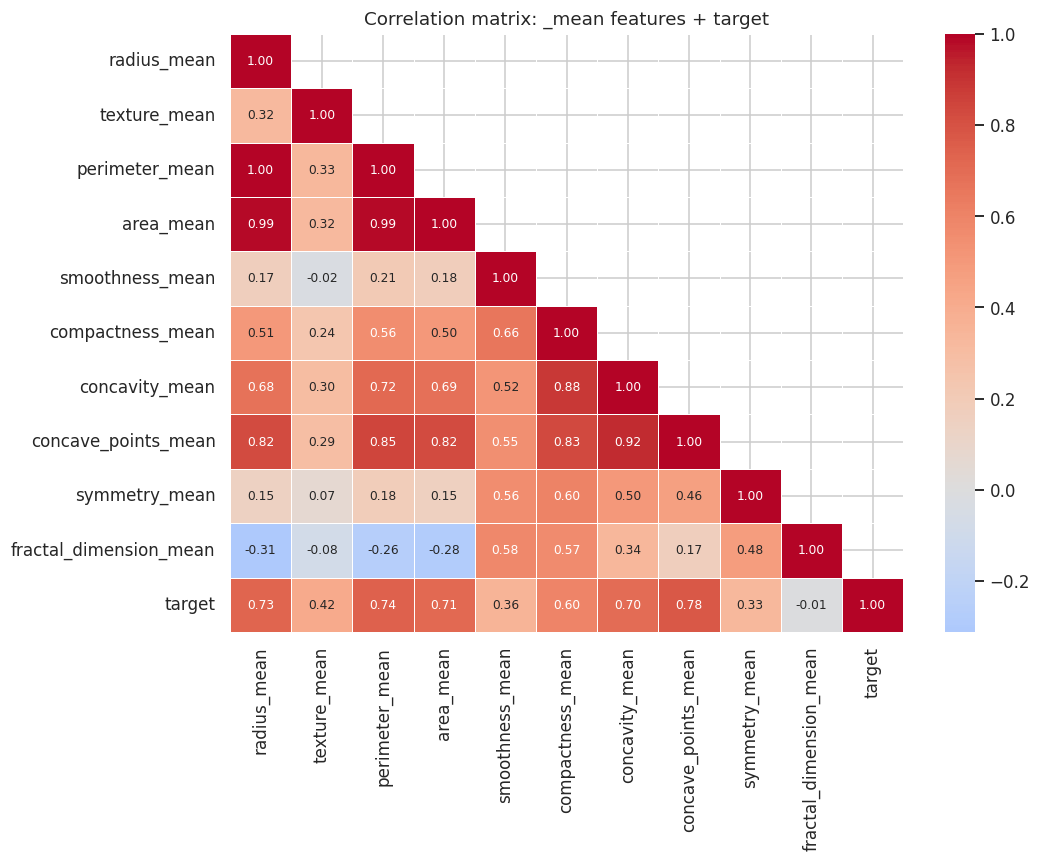

In [13]:
corr = df[mean_cols + ["target"]].corr()
mask = np.triu(np.ones_like(corr, dtype=bool), k=1)
fig, ax = plt.subplots(figsize=(10, 8))
sns.heatmap(corr, mask=mask, cmap="coolwarm", center=0, annot=True, fmt=".2f",
            annot_kws={"size": 8}, linewidths=0.5, ax=ax)
ax.set_title("Correlation matrix: _mean features + target")
plt.tight_layout(); plt.show()

In [14]:
# Highly redundant pairs across ALL 30 features
c = df[features].corr().abs()
upper_tri = c.where(np.triu(np.ones(c.shape), k=1).astype(bool))
pairs = upper_tri.stack().sort_values(ascending=False)
print("Feature pairs with |r| > 0.9:", (pairs > 0.9).sum())
pairs.head(8).round(3)

Feature pairs with |r| > 0.9: 21


,,0
radius_mean,perimeter_mean,0.998
radius_worst,perimeter_worst,0.994
radius_mean,area_mean,0.987
perimeter_mean,area_mean,0.987
radius_worst,area_worst,0.984
perimeter_worst,area_worst,0.978
radius_se,perimeter_se,0.973
perimeter_mean,perimeter_worst,0.970


`radius`, `perimeter` and `area` are almost perfectly correlated (r > 0.98). They are geometrically linked measures of the same thing: nucleus size. 21 feature pairs exceed |r| = 0.9, so linear models will suffer from multicollinearity unless features are pruned or regularized.

### Chart 5 — Which features relate most to malignancy? (bar plot)

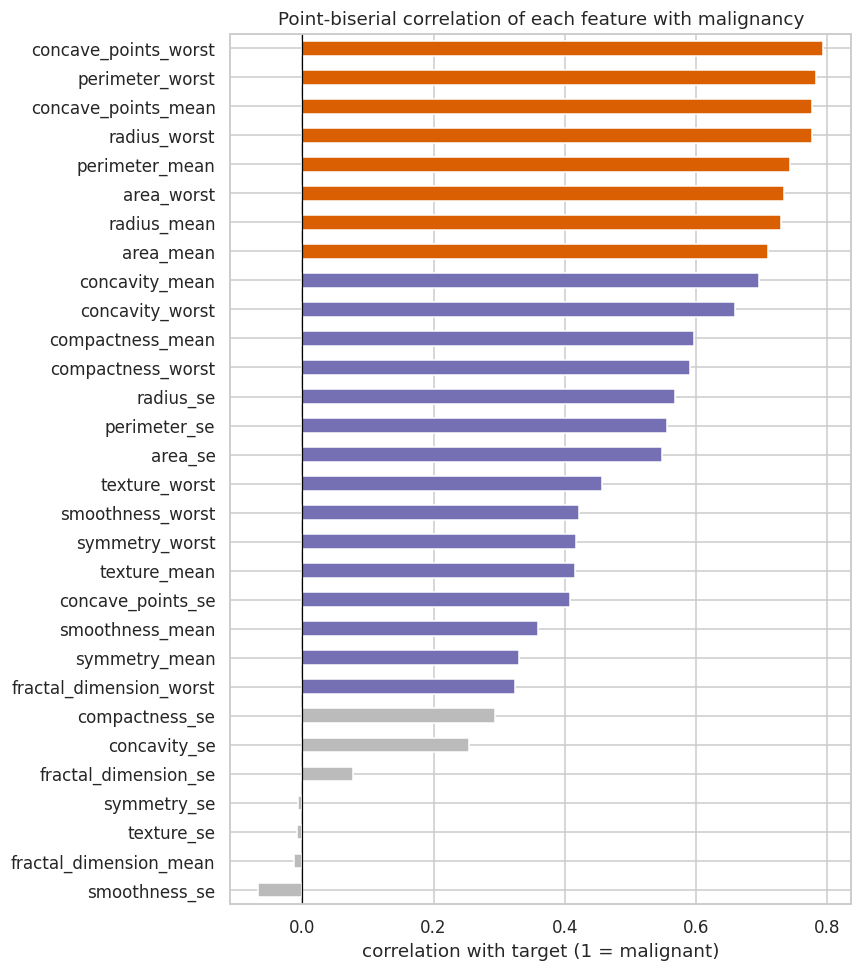

In [15]:
target_corr = df[features].corrwith(df["target"]).sort_values()
colors = ["#d95f02" if v > 0.7 else "#7570b3" if v > 0.3 else "#bbbbbb" for v in target_corr]
fig, ax = plt.subplots(figsize=(8, 9))
target_corr.plot.barh(color=colors, ax=ax)
ax.axvline(0, color="black", lw=0.8)
ax.set_title("Point-biserial correlation of each feature with malignancy")
ax.set_xlabel("correlation with target (1 = malignant)")
plt.tight_layout(); plt.show()

The `_worst` versions of concave points, perimeter and radius are the strongest single predictors (r ≈ 0.78–0.79). The bottom of the chart (`smoothness_se`, `fractal_dimension_mean`, `texture_se`, `symmetry_se`) has near-zero correlation, so these are candidates for removal.

### Chart 6 — Two features together (scatter)

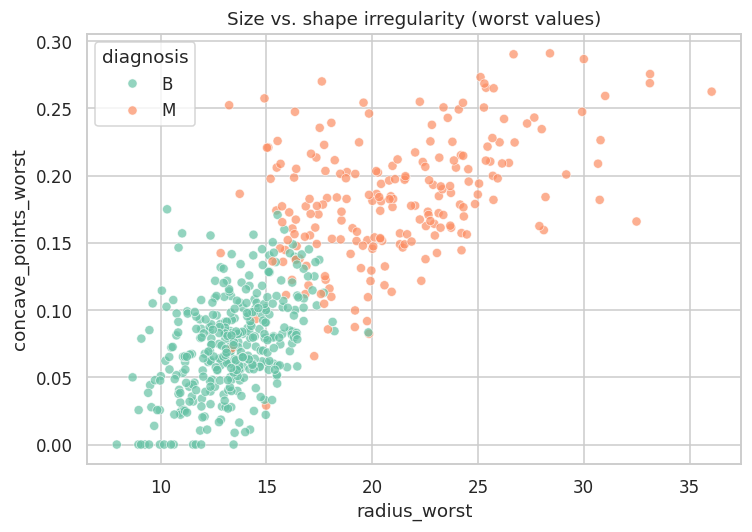

In [16]:
fig, ax = plt.subplots(figsize=(7, 5))
sns.scatterplot(data=df, x="radius_worst", y="concave_points_worst", hue="diagnosis",
                hue_order=order, alpha=0.7, ax=ax)
ax.set_title("Size vs. shape irregularity (worst values)")
plt.tight_layout(); plt.show()

Two features alone (one for size, one for shape) already separate the classes almost cleanly, with overlap only in a narrow band. This suggests even a simple model will perform well.

## 3. Feature Engineering

Four new features, each grounded in what the EDA showed:

| Feature | Formula | Rationale |
|---|---|---|
| `circularity_ratio` | perimeter² / (4π · area) | Equals 1.0 for a perfect circle; higher means a more irregular outline. Combines two redundant size features into one *shape* feature. |
| `worst_to_mean_radius` | radius_worst / radius_mean | How much the largest nuclei exceed the typical one. Captures **heterogeneity** within the sample. |
| `concavity_burden` | concave_points_worst × radius_worst | Interaction of the two strongest predictors: large *and* irregular nuclei. |
| `log_area_se` | log(1 + area_se) | `area_se` is the most outlier-heavy feature (heavy right skew); a log transform normalizes it. |

In [17]:
def add_features(d):
    d = d.copy()
    d["circularity_ratio"]    = d["perimeter_mean"] ** 2 / (4 * np.pi * d["area_mean"])
    d["worst_to_mean_radius"] = d["radius_worst"] / d["radius_mean"]
    d["concavity_burden"]     = d["concave_points_worst"] * d["radius_worst"]
    d["log_area_se"]          = np.log1p(d["area_se"])
    return d

df       = add_features(df)
df_model = add_features(df_model)
new_feats = ["circularity_ratio", "worst_to_mean_radius", "concavity_burden", "log_area_se"]

summary = pd.DataFrame({
    "median_B": df[df.diagnosis == "B"][new_feats].median(),
    "median_M": df[df.diagnosis == "M"][new_feats].median(),
    "corr_with_target": df[new_feats].corrwith(df["target"]),
}).round(3)
summary

,median_B,median_M,corr_with_target
circularity_ratio,1.066,1.111,0.506
worst_to_mean_radius,1.099,1.198,0.641
concavity_burden,0.991,3.745,0.800
log_area_se,3.027,4.085,0.725


In [18]:
# Compare skew before/after the log transform
print("Skew area_se    :", round(df["area_se"].skew(), 2))
print("Skew log_area_se:", round(df["log_area_se"].skew(), 2))

Skew area_se    : 5.45
Skew log_area_se: 0.85


### Chart 7 — Engineered features by diagnosis

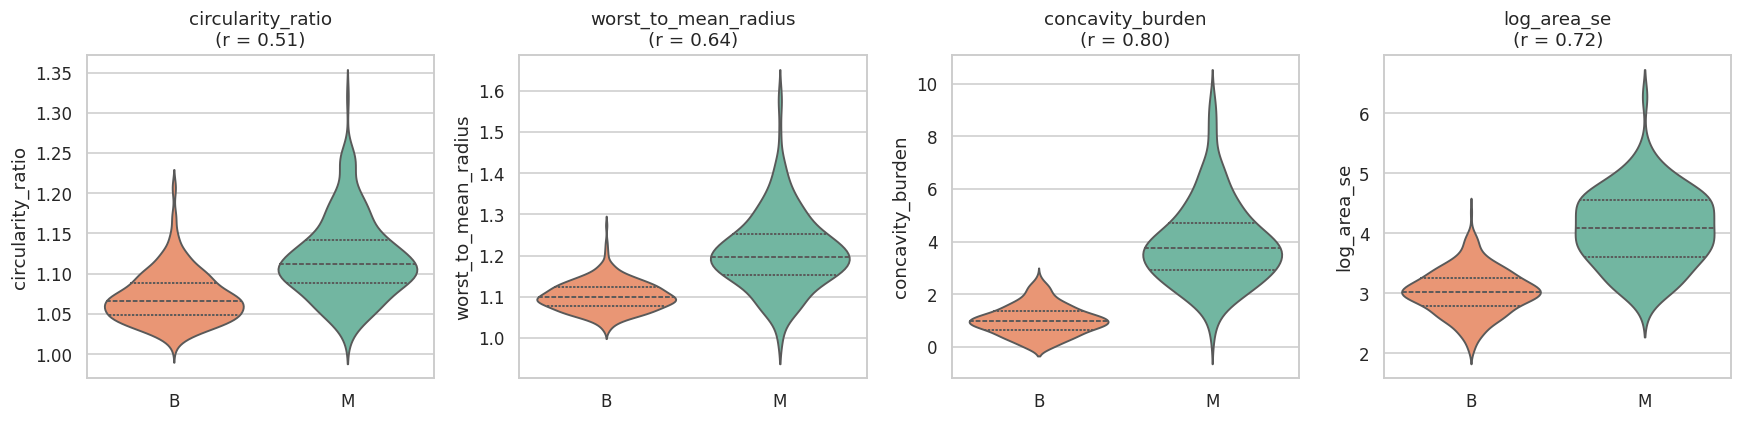

In [19]:
fig, axes = plt.subplots(1, 4, figsize=(16, 4))
for ax, col in zip(axes, new_feats):
    sns.violinplot(data=df, x="diagnosis", y=col, order=order, hue="diagnosis",
                   legend=False, inner="quartile", ax=ax)
    ax.set_title(f"{col}\n(r = {df[col].corr(df['target']):.2f})")
    ax.set_xlabel("")
plt.tight_layout(); plt.show()

- **`concavity_burden`** (r ≈ 0.80) edges out the best raw feature (`concave_points_worst`, r ≈ 0.79) by combining size and shape in one column.
- **`log_area_se`** jumps from r ≈ 0.55 for raw `area_se` to ≈ 0.73, and its skew drops sharply. The transform made the signal usable for linear models.
- **`worst_to_mean_radius`** (r ≈ 0.64) is new information: it isn't strongly tied to any single raw column, and malignant samples show clearly more nucleus-to-nucleus variation.
- **`circularity_ratio`** (r ≈ 0.51) is weaker but turns three near-duplicate size columns into an independent shape signal.

### Final model-ready dataset

In [21]:
X = df_model[features + new_feats]
y = df_model["target"]
print("X:", X.shape, "| y:", y.shape, "| nulls:", X.isna().sum().sum())
# Optional: save for the next (modeling) step
# df_model.to_csv("data_clean_features.csv", index=False)

X: (569, 34) | y: (569,) | nulls: 0


## 4. Key Insights

1. **The data is clean apart from one artifact.** The only missing values were in an empty trailing column (`Unnamed: 32`), with no duplicate rows or ids. The 13 zero-concavity rows are real (all benign, smooth nuclei) and not hidden missing data.
2. **Outliers are signal, not noise.** About 30% of rows contain at least one IQR outlier, and 67% of those rows are malignant, compared with 37% overall. Dropping them would remove the minority class, so I kept every row and only capped values at the 1st/99th percentile for the modeling copy.
3. **Nucleus size and contour concavity are the dominant signals.** `concave_points_worst`, `perimeter_worst` and `radius_worst` each correlate ≈ 0.78–0.79 with malignancy. The median malignant nucleus is about 2× the area of a benign one, and its concave-points score is several times higher. A two-feature scatter plot already almost separates the classes.
4. **Heavy redundancy: 21 feature pairs have |r| > 0.9.** Radius, perimeter and area are effectively the same measurement (r > 0.98). A linear model will need feature pruning, PCA or regularization. Meanwhile, `fractal_dimension_mean`, `symmetry_se`, `texture_se` and `smoothness_se` carry almost no class signal.
5. **Engineered features add measurable value.** `concavity_burden` (size × concave points) is the single strongest predictor in the dataset (r ≈ 0.80). Log-transforming `area_se` raised its correlation from ≈ 0.55 to ≈ 0.73. `worst_to_mean_radius` captures heterogeneity within each sample, which no raw column measures directly.

